### Imported the required libraries

In [1]:
import pandas as pd

### Loaded the csv file

In [2]:
df = pd.read_csv("./Data/after_preprocess.csv")

### printed the first few rows of the dataframe

In [3]:
df.head()

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-01-31,CS,1.0,1,2020,4,2020-02-01,1.0,2020-01-11,20.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-01,CS,0.5,2,2020,5,2020-02-15,14.0,2020-01-31,1.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-15,AL,0.5,2,2020,5,2020-02-18,3.0,2020-02-01,14.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-18,CS,1.0,2,2020,1,2020-03-10,21.0,2020-02-15,3.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-03-10,CS,1.0,3,2020,1,2020-06-11,93.0,2020-02-18,21.0,6


### Dropped the unnecessary columns 

In [4]:
df = df.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE', 'DAYS UNTIL NEXT LEAVE'])
df

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2020,4,20.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,0.5,2,2020,5,1.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,0.5,2,2020,5,14.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,2,2020,1,3.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,3,2020,1,21.0,6
...,...,...,...,...,...,...,...,...,...,...,...
229370,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,10,2024,0,5.0,5
229371,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,10,2024,1,1.0,6
229372,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,1,2025,3,100.0,1
229373,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,1,2025,0,4.0,2


### Creating the feature variable

In [5]:
X = df.drop(columns=['TYPE'],axis=1)
X.head()

,NAME,DIV,DEP,LOC,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,1.0,1,2020,4,20.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,0.5,2,2020,5,1.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,0.5,2,2020,5,14.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,1.0,2,2020,1,3.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,1.0,3,2020,1,21.0,6


### Created the feature variable

In [6]:
y = df['TYPE']
y

0         CS
1         CS
2         AL
3         CS
4         CS
          ..
229370    SK
229371    SK
229372    SK
229373    SK
229374    CS
Name: TYPE, Length: 229375, dtype: object

### Created column transformer pipeline

In [7]:
from sklearn.impute import SimpleImputer

# Create Column Transformer with 3 types of transformers
numerical_columns = ['NO DAYS', 'LEAVE MONTH', 'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'DAYS SINCE LAST LEAVE', 'CUMULATIVE LEAVE COUNT']
categorical_columns = ['NAME', 'DIV', 'DEP', 'LOC']

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")), #handling missing values
        ("scaler", StandardScaler(with_mean=False))
    ]
)

cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown='ignore')),
        ("scaler", StandardScaler(with_mean=False))
    ]
)

preprocessor = ColumnTransformer([
    ("num_pipeline", num_pipeline, numerical_columns),
    ("cat_pipeline", cat_pipeline, categorical_columns)
])

### Transformed the feature variable using the pipeline

In [8]:
X = preprocessor.fit_transform(X)

In [9]:
X.shape

(229375, 1682)

### Split the dataset for training and testing

In [48]:
# separate dataset into train and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape, X_test.shape

((183500, 1682), (45875, 1682))

### Random forest

In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Step 1: Initialize the RandomForestClassifier
classifier = RandomForestClassifier(random_state=42)

# Step 2: Train the model on the preprocessed training data
classifier.fit(X_train, y_train)

# Step 3: Make predictions on the test set
y_pred = classifier.predict(X_test)

# Step 4: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of the model: {accuracy:.2f}")

# Step 5: Print a detailed classification report (optional)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy of the model: 0.60
Classification Report:
              precision    recall  f1-score   support

          AC       0.91      0.76      0.83       221
          AL       0.59      0.73      0.65     18849
          CP       0.84      0.82      0.83       986
          CS       0.43      0.23      0.30      9464
          IN       1.00      0.91      0.95        11
          LD       0.95      0.79      0.86       144
          MA       0.50      0.24      0.32        21
          ML       0.99      0.96      0.97       116
          MT       1.00      1.00      1.00        17
          QU       0.79      0.67      0.72       848
          SD       0.63      0.53      0.58      1258
          SK       0.64      0.66      0.65     13263
          SP       0.83      0.33      0.48       547
          SS       1.00      1.00      1.00         3
          SU       1.00      0.44      0.62         9
          TD       0.81      0.74      0.77       118

    accuracy                 

### KNeighbors

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          AC       0.67      0.75      0.71       221
          AL       0.55      0.67      0.61     18849
          CP       0.53      0.73      0.61       986
          CS       0.37      0.26      0.30      9464
          IN       0.85      1.00      0.92        11
          LD       0.62      0.76      0.68       144
          MA       0.14      0.05      0.07        21
          ML       0.93      0.98      0.95       116
          MT       0.94      1.00      0.97        17
          QU       0.49      0.54      0.51       848
          SD       0.30      0.19      0.23      1258
          SK       0.62      0.57      0.59     13263
          SP       0.68      0.31      0.43       547
          SS       0.33      0.33      0.33         3
          SU       1.00      0.33      0.50         9
          TD       0.67      0.61      0.64       118

    accuracy                           0.54     45875
   macro avg       0.60   

### Neural network

### Function to plot the graphs

In [25]:
from matplotlib import pyplot as plt

def plot_history(history):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4))
  ax1.plot(history.history['loss'], label='loss')
  ax1.plot (history. history['val_loss'], label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary crossentropy')
  ax1.grid(True)

  ax2.plot(history.history['accuracy'], label='accuracy')
  ax2.plot(history.history['val_accuracy'], label='val _accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('Accuracy')
  ax2.grid(True)

  plt.show()

#### Encoding the feature variable for the neural network

In [30]:
from sklearn.preprocessing import LabelEncoder
# Step 2: Encode target variable y_train
label_encoder = LabelEncoder()
sample = y_train
y_train = label_encoder.fit_transform(y_train)

#### Defining the neural network

In [36]:
import tensorflow as tf

def train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, num_classes):
    # Define the neural network model
    nn_model = tf.keras.Sequential([
        tf.keras.layers.Dense(num_nodes, activation='relu'),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation='relu'),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_classes, activation='softmax')  # Output layer for multi-class classification
    ])
    
    # Compile the model
    nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                     loss='sparse_categorical_crossentropy',  # Loss function for multi-class classification
                     metrics=['accuracy'])  # Track accuracy during training
    
    # Train the model
    history = nn_model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,  # Use 20% of the data for validation
        verbose=1  # Set to 1 to see training progress
    )
    
    return nn_model, history

In [45]:
# Number of unique leave types
num_classes = len(label_encoder.classes_)

# Train the model
model, history = train_model(
    X_train, y_train,
    num_nodes=64,          # Number of nodes in hidden layers
    dropout_prob=0.2,      # Dropout probability
    lr=0.001,              # Learning rate
    batch_size=64,        # Batch size
    epochs=100,             # Number of epochs
    num_classes=num_classes
)


Epoch 1/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.3653 - loss: 3.0539 - val_accuracy: 0.4825 - val_loss: 1.3264
Epoch 2/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4663 - loss: 1.3444 - val_accuracy: 0.4821 - val_loss: 1.3066
Epoch 3/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4803 - loss: 1.3060 - val_accuracy: 0.4908 - val_loss: 1.2720
Epoch 4/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4835 - loss: 1.2902 - val_accuracy: 0.4709 - val_loss: 1.2796
Epoch 5/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4868 - loss: 1.2712 - val_accuracy: 0.4795 - val_loss: 1.2489
Epoch 6/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step - accuracy: 0.4839 - loss: 1.2656 - val_accuracy: 0.4698 - val_loss: 1.2505
Epoch 7/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4855 - loss: 1.2541 - val_accuracy: 0.4967 - val_loss: 1.2227
Epoch 8/100
2294/2294 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4939 - loss: 1

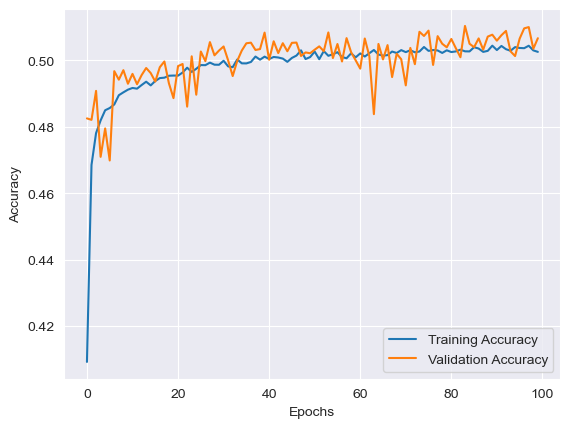

Final Training Accuracy: 0.50
Final Validation Accuracy: 0.51


In [46]:
# Plot training and validation accuracy
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Print final accuracy
final_training_accuracy = history.history['accuracy'][-1]
final_validation_accuracy = history.history['val_accuracy'][-1]
print(f"Final Training Accuracy: {final_training_accuracy:.2f}")
print(f"Final Validation Accuracy: {final_validation_accuracy:.2f}")